Perform medical diagnosis classification

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("/content/medical_diagnosis_classification.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 265 entries, 0 to 264
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   blood_sugar     241 non-null    object 
 1   bmi_dup         239 non-null    float64
 2   sex             246 non-null    object 
 3   age             245 non-null    float64
 4   blood_pressure  246 non-null    object 
 5   cholesterol     234 non-null    float64
 6   smoker          248 non-null    object 
 7   bmi             239 non-null    float64
 8   patient_id      243 non-null    object 
 9   disease         237 non-null    float64
dtypes: float64(5), object(5)
memory usage: 20.8+ KB


In [3]:
df.head()

,blood_sugar,bmi_dup,sex,age,blood_pressure,cholesterol,smoker,bmi,patient_id,disease
0,High,NaN,M,89.0,109.9,203.0,No,NaN,P40000,1.0
1,Lw,29.0,F,88.0,118.7,165.9,NO,29.0,NaN,0.0
2,HIGH,19.2,M,80.0,107.5,166.8,Yes,19.2,P40002,0.0
3,High,22.0,M,NaN,121.3,204.7,N,22.0,P40003,0.0
4,NORMAL,28.0,M,36.0,unknown,202.7,Yes,28.0,P40004,0.0


#duplicated() is used to check if there are any duplicate rows in a data set. If so, it returns True else False.

In [9]:
df.duplicated()


,0
0,False
1,False
2,False
3,False
4,False
...,...
245,False
246,False
247,False
248,False


#drop_duplicates() removes the first occurence of duplicate rows in a data set

In [10]:

df.drop_duplicates(inplace = True)
df

,blood_sugar,bmi_dup,sex,age,blood_pressure,cholesterol,smoker,bmi,patient_id,disease
0,High,NaN,M,89.0,109.9,203.0,No,NaN,P40000,1.0
1,Lw,29.0,F,88.0,118.7,165.9,NO,29.0,NaN,0.0
2,HIGH,19.2,M,80.0,107.5,166.8,Yes,19.2,P40002,0.0
3,High,22.0,M,NaN,121.3,204.7,N,22.0,P40003,0.0
4,NORMAL,28.0,M,36.0,unknown,202.7,Yes,28.0,P40004,0.0
...,...,...,...,...,...,...,...,...,...,...
245,Low,17.3,F,NaN,97.9,203.7,No,17.3,P40245,0.0
246,NORMAL,30.5,M,78.0,97.6,218.7,N,30.5,P40246,0.0
247,Low,19.1,F,80.0,130.9,248.4,o,19.1,P40247,0.0
248,Hih,16.9,M,NaN,107.7,229.2,No,16.9,P40248,1.0


drop() method is used to drop the specific column

In [11]:
df = df.drop(columns=['bmi_dup'])
df.head()

,blood_sugar,sex,age,blood_pressure,cholesterol,smoker,bmi,patient_id,disease
0,High,M,89.0,109.9,203.0,No,NaN,P40000,1.0
1,Lw,F,88.0,118.7,165.9,NO,29.0,NaN,0.0
2,HIGH,M,80.0,107.5,166.8,Yes,19.2,P40002,0.0
3,High,M,NaN,121.3,204.7,N,22.0,P40003,0.0
4,NORMAL,M,36.0,unknown,202.7,Yes,28.0,P40004,0.0


 Display missing values

In [12]:
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
blood_sugar       22
sex               19
age               19
blood_pressure    19
cholesterol       30
smoker            17
bmi               25
patient_id        22
disease           24
dtype: int64


Smoking distribution in medical diagnosis

In [16]:
print("\nSmoking distribution:")
print(df["smoker"].value_counts())


Smoking distribution:
smoker
No     88
NO     47
N      32
o      26
Yes    21
YES    10
Ye      4
es      3
Ys      2
Name: count, dtype: int64


Average age by disease

In [19]:
print("\nAverage age by disease:")
print(df.groupby("disease")["age"].mean())



Average age by disease:
disease
0.0    51.794286
1.0    50.878788
Name: age, dtype: float64


To apply mean and mode for the numerical data and categorical data

In [20]:
num_cols = df.select_dtypes(include=["float64", "int64"]).columns
cat_cols = df.select_dtypes(include=["object"]).columns
for col in num_cols:
    df[col] = df[col].fillna(df[col].mean())
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])
df.isnull().sum()

,0
blood_sugar,0
sex,0
age,0
blood_pressure,0
cholesterol,0
smoker,0
bmi,0
patient_id,0
disease,0


Handling inconsistent values

In [22]:
smoker_map = {
    'No': 'No', 'NO': 'No', 'N': 'No', 'o': 'No',
    'Yes': 'Yes', 'YES': 'Yes', 'Ye': 'Yes', 'es': 'Yes', 'Ys': 'Yes'
}
df['smoker'] = df['smoker'].map(smoker_map)

sugar_map = {
    'High': 'High', 'HIGH': 'High', 'Hih': 'High',
    'Lw': 'Low', 'Low': 'Low',
    'NORMAL': 'Normal', 'Normal': 'Normal'
}
df['blood_sugar'] = df['blood_sugar'].map(sugar_map)
df['blood_pressure'] = pd.to_numeric(df['blood_pressure'].replace('unknown', np.nan), errors='coerce')
df['blood_pressure'] = df['blood_pressure'].fillna(df['blood_pressure'].mean())
print("Cleaned Smoker counts:\n", df['smoker'].value_counts(dropna=False))
print("\nCleaned Blood Sugar counts:\n", df['blood_sugar'].value_counts(dropna=False))

Cleaned Smoker counts:
 smoker
No     210
Yes     40
Name: count, dtype: int64

Cleaned Blood Sugar counts:
 blood_sugar
Low       76
Normal    63
High      59
NaN       52
Name: count, dtype: int64


visualization means representing your dataset using graphs and charts

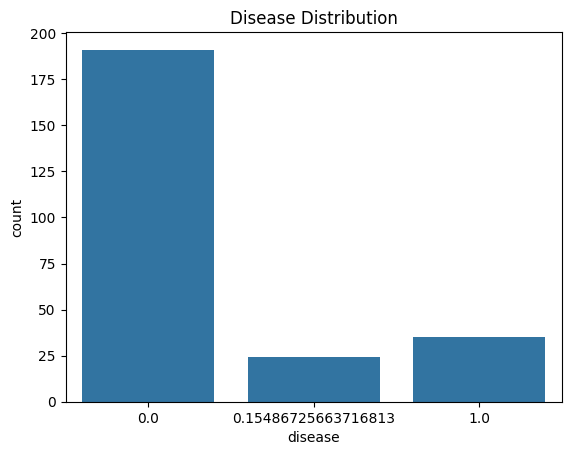

In [32]:
sns.countplot(data=df, x="disease")
plt.title("Disease Distribution")
plt.show()

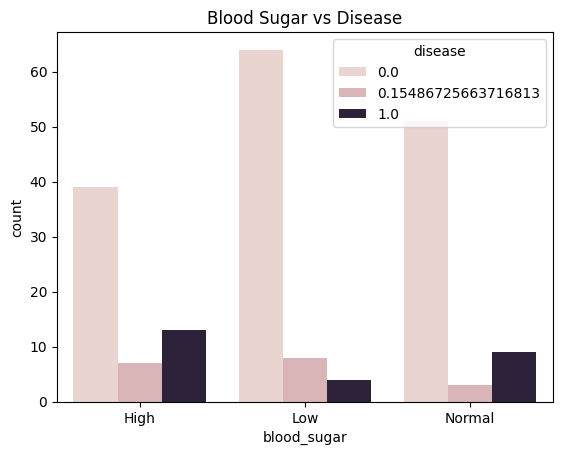

In [29]:
sns.countplot(data=df, x="blood_sugar", hue="disease")
plt.title("Blood Sugar vs Disease")
plt.show()


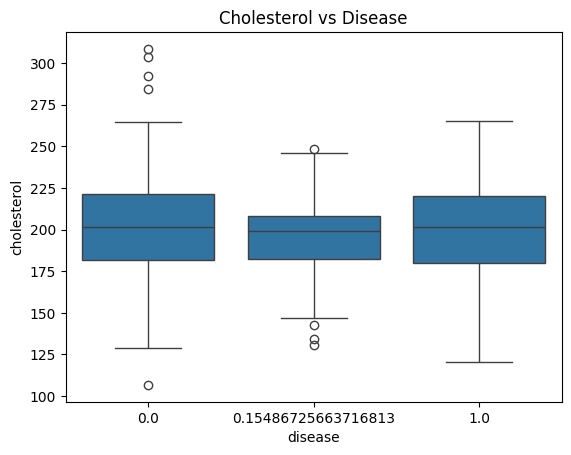

In [28]:
sns.boxplot(data=df, x="disease", y="cholesterol")
plt.title("Cholesterol vs Disease")
plt.show()

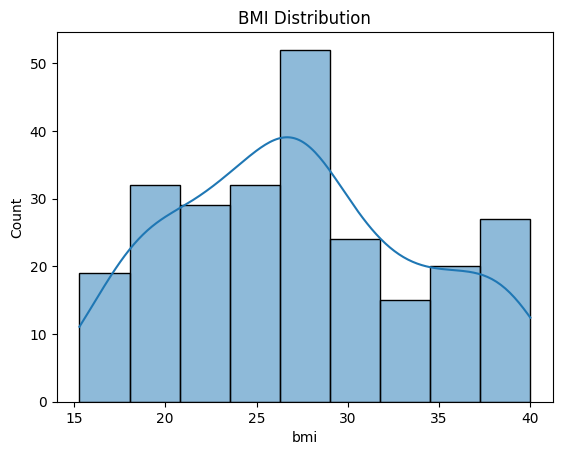

In [27]:
sns.histplot(data=df, x="bmi", kde=True)
plt.title("BMI Distribution")
plt.show()

To show the relationship between two numerical variables using scatterplot

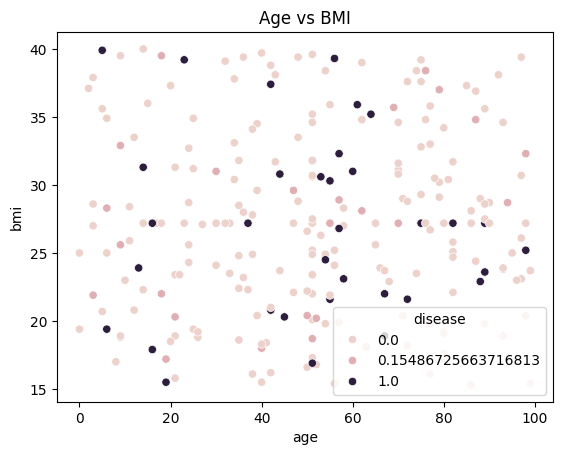

In [33]:
sns.scatterplot(data=df, x="age", y="bmi",
                hue="disease")
plt.title("Age vs BMI")
plt.show()


/tmp/ipykernel_5496/320432800.py:1: UserWarning: 
The palette list has fewer values (2) than needed (3) and will cycle, which may produce an uninterpretable plot.
  sns.scatterplot(data=df, x="bmi", y="blood_pressure",


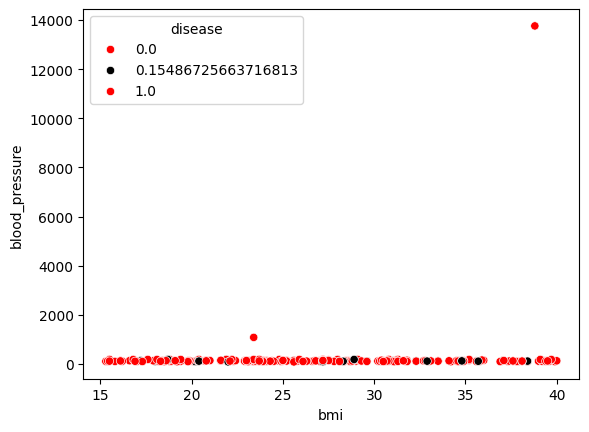

In [34]:
sns.scatterplot(data=df, x="bmi", y="blood_pressure",
                hue="disease",
                palette=["red", "black"])
plt.show()

/tmp/ipykernel_5496/3502013144.py:1: UserWarning: 
The palette list has fewer values (2) than needed (3) and will cycle, which may produce an uninterpretable plot.
  sns.countplot(data=df, x="blood_sugar",


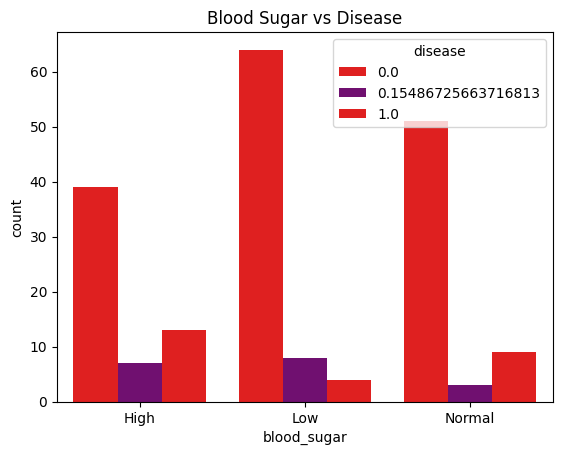

In [36]:
sns.countplot(data=df, x="blood_sugar",
              hue="disease",
              palette=["red", "purple"])
plt.title("Blood Sugar vs Disease")
plt.show()

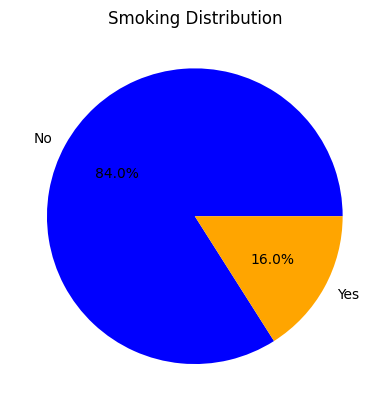

In [38]:
df["smoker"].value_counts().plot.pie(
    autopct="%1.1f%%",
    colors=["blue", "orange"]
)

plt.title("Smoking Distribution")
plt.ylabel("")
plt.show()

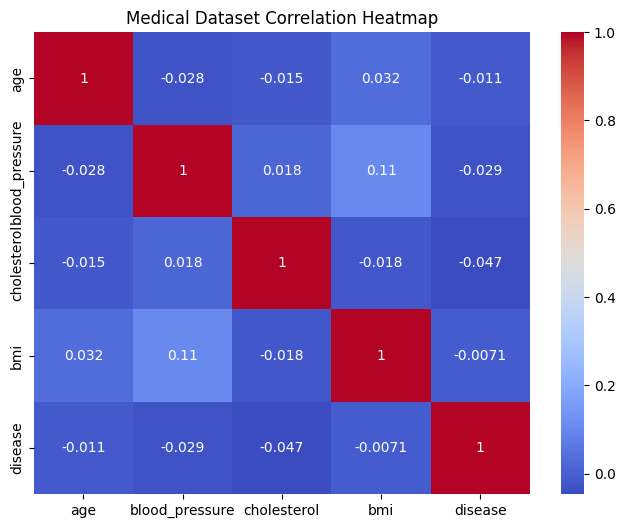

In [39]:
plt.figure(figsize=(8,6))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Medical Dataset Correlation Heatmap")
plt.show()